<a href="https://colab.research.google.com/github/Vishesh-Goyal7/NARAD-QC/blob/main/NARAD_QC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NARAD-QC
### Network Architecture for Routing, Authentication and Delivery in Quantum Communications

## Phase 0 : 06-07-2026T16:15:32 -- 06-07-2026T16:48:53

Goal : Rebuild point to point CrypTon key generation and AES baseline.

Objective : Prove the original point-to-point system is working as the baseline.

In [ ]:
# @title Dependency Installation for Phase 0

!pip install qiskit qiskit-aer pycryptodome pandas matplotlib --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 156.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 124.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 105.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 112.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 6.3 MB/s eta 0:00:00


In [ ]:
# @title Imports and Global Config

import time
import secrets
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

RNG = np.random.default_rng()
BACKEND = AerSimulator()

QBER_CUTOFF = 0.11
NONCE_LEN = 12

In [ ]:
# @title AES-GCM Engine

def aes_gcm_encrypt(data: bytes, key: bytes) -> bytes:
    nonce = get_random_bytes(NONCE_LEN)
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    ciphertext, tag = cipher.encrypt_and_digest(data)
    return nonce + ciphertext + tag


def aes_gcm_decrypt(blob: bytes, key: bytes) -> bytes:
    nonce = blob[:NONCE_LEN]
    rest = blob[NONCE_LEN:]
    ciphertext = rest[:-16]
    tag = rest[-16:]

    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    return cipher.decrypt_and_verify(ciphertext, tag)

In [ ]:
# @title BB84 Step 1 : QRNG

def random_bitstring(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()


def random_bases(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()

In [ ]:
# @title BB84 Step 2 : Qubit Encoding

def encode_qubits(bits: list[int], bases: list[int]) -> list[QuantumCircuit]:
    circuits = []

    for bit, basis in zip(bits, bases):
        qc = QuantumCircuit(1, 1)

        if bit == 1:
            qc.x(0)

        if basis == 1:
            qc.h(0)

        circuits.append(qc)

    return circuits

In [ ]:
# @title BB84 Step 3 : Measure Qubits With Photon Loss Support

def measure_qubits(
    qubits: list,
    bob_bases: list[int],
    eve_present: bool = False
) -> list:

    measured_bits = []

    for i, prepared_qubit in enumerate(qubits):

        # Photon lost in QuantumLink
        if prepared_qubit is None:
            measured_bits.append(None)
            continue

        circuit = prepared_qubit.copy()

        if eve_present:
            eve_basis = int(RNG.integers(0, 2))

            eve_circuit = circuit.copy()

            if eve_basis == 1:
                eve_circuit.h(0)

            eve_circuit.measure(0, 0)

            transpiled_eve = transpile(eve_circuit, BACKEND)
            eve_result = BACKEND.run(
                transpiled_eve,
                shots=1,
                memory=True
            ).result()

            eve_bit = int(eve_result.get_memory()[0])

            circuit = QuantumCircuit(1, 1)

            if eve_bit == 1:
                circuit.x(0)

            if eve_basis == 1:
                circuit.h(0)

        if bob_bases[i] == 1:
            circuit.h(0)

        circuit.measure(0, 0)

        transpiled_bob = transpile(circuit, BACKEND)
        bob_result = BACKEND.run(
            transpiled_bob,
            shots=1,
            memory=True
        ).result()

        measured_bits.append(int(bob_result.get_memory()[0]))

    return measured_bits

In [ ]:
# @title QBER, Sifting, and Key Reconciliation With Photon Loss

def sift_keys(
    alice_bits: list[int],
    alice_bases: list[int],
    bob_bits: list,
    bob_bases: list[int]
) -> tuple[list[int], list[int]]:

    alice_sifted = []
    bob_sifted = []

    for i in range(len(alice_bits)):
        if bob_bits[i] is None:
            continue

        if alice_bases[i] == bob_bases[i]:
            alice_sifted.append(alice_bits[i])
            bob_sifted.append(bob_bits[i])

    return alice_sifted, bob_sifted

def calculate_qber(alice_key: list[int], bob_key: list[int]) -> float:
    if len(alice_key) == 0:
        return 1.0

    errors = sum(a != b for a, b in zip(alice_key, bob_key))
    return errors / len(alice_key)

In [ ]:
# @title One BB84 Round

def bb84_round(
    n_qubits: int = 256,
    eve_present: bool = False
) -> dict:

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits)
    bob_bases = random_bases(n_qubits)

    qubits = encode_qubits(alice_bits, alice_bases)
    bob_bits = measure_qubits(qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)

    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present
    }

In [ ]:
# @title Accumulate Session Key

def bits_to_bytes(bits: list[int]) -> bytes:
    usable_len = len(bits) - (len(bits) % 8)
    bits = bits[:usable_len]

    return bytes(
        int("".join(map(str, bits[i:i+8])), 2)
        for i in range(0, usable_len, 8)
    )


def generate_bb84_session_key(
    target_bits: int = 128,
    n_qubits_per_round: int = 256,
    max_rounds: int = 30,
    eve_present: bool = False,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):
        result = bb84_round(
            n_qubits=n_qubits_per_round,
            eve_present=eve_present
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"]
        })

        if verbose:
            print(
                f"Round {round_id}: "
                f"sifted={result['sifted_length']}, "
                f"QBER={result['qber']:.2%}, "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    metadata = {
        "target_bits": target_bits,
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_sifted_bits": sum(r["sifted_length"] for r in round_logs),
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Phase 0 End to End System COMMENTED OUT

# message = b"NARAD-QC Phase 0: CrypTon baseline reconstruction."

# session_key, meta = generate_bb84_session_key(
#     target_bits=128,
#     n_qubits_per_round=256,
#     max_rounds=30,
#     eve_present=False,
#     verbose=True
# )

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\nSession Key:", session_key.hex())
# print("Key Metadata:", meta)
# print("Ciphertext:", ciphertext.hex())
# print("Decrypted:", decrypted.decode())
# print("Roundtrip OK:", decrypted == message)

In [ ]:
# @title Eve Presence Validation

# try:
#     eve_key, eve_meta = generate_bb84_session_key(
#         target_bits=128,
#         n_qubits_per_round=256,
#         max_rounds=5,
#         eve_present=True,
#         verbose=True
#     )

#     print("Unexpectedly generated key with Eve present.")
#     print(eve_meta)

# except RuntimeError as e:
#     print("Eve disrupted key generation as expected.")
#     print(str(e))

## Phase 1 : 06-07-2026T17:08:12 -- 07-07-2026T16:37:51

Goal : Add distance-dependent photon loss, QBER, keygen latency, and accepted/rejected rounds.

Objective : Evaluate how distance affects QKD in terms of photon loss, QBER, Key generation latency.

Question : How does increasing physical separation affect secure key establishment in CrypTon?

### Phase 1A

QuantumLink and Node classes

In [ ]:
# @title Node Class Definition

ROLE_USER = "USER"
ROLE_REPEATER = "REPEATER"

class Node:
    def __init__(self, name: str, role: str):
        self.name = name
        self.role = role

    def __str__(self):
        return f"{self.name} ({self.role})"

In [ ]:
# @title Create 2 User Nodes

alice = Node(name="Alice", role=ROLE_USER)
bob = Node(name="Bob", role=ROLE_USER)

print(alice)
print(bob)

Alice (USER)
Bob (USER)


In [ ]:
# @title Quantum Link Class

import random
import math

STANDARD_FIBER_ATTENUATION = 0.2  # dB/km


class QuantumLink:
    """
    NARAD-QC Phase 1.1 / 1.2

    Models a physical quantum channel with distance-dependent photon loss.
    Lost photons are represented as None.
    """

    def __init__(
        self,
        source: Node,
        destination: Node,
        distance_km: float,
        attenuation_db_per_km: float = STANDARD_FIBER_ATTENUATION
    ):
        self.source = source
        self.destination = destination
        self.distance_km = distance_km
        self.attenuation = attenuation_db_per_km
        self.status = "ACTIVE"

        # η(d) = 10^(-(αd)/10)
        self.survival_probability = 10 ** (
            -(self.attenuation * self.distance_km) / 10
        )

        self.loss_probability = 1 - self.survival_probability

        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def transmit(self, qubit):
        """
        Transmit one qubit through the quantum link.
        Returns the qubit if it survives, otherwise None.
        """

        self.statistics["lifetime_sent"] += 1

        if random.random() < self.survival_probability:
            self.statistics["lifetime_received"] += 1
            return qubit

        self.statistics["lifetime_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        """
        Transmit a batch of qubits.

        Returns:
        - transmitted_qubits: list containing QuantumCircuit objects or None
        - session-level transmission statistics
        """

        transmitted_qubits = []
        survived = 0

        for qubit in qubits:
            received = self.transmit(qubit)
            transmitted_qubits.append(received)

            if received is not None:
                survived += 1

        sent = len(qubits)
        lost = sent - survived

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": survived,
            "lost": lost,
            "expected_survival_probability": self.survival_probability,
            "observed_survival_probability": survived / sent if sent else 0,
            "survival_percentage": (survived / sent) * 100 if sent else 0
        }

    def reset_statistics(self):
        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def __str__(self):
        return (
            f"\n{'='*60}\n"
            f"Quantum Link\n"
            f"{'='*60}\n"
            f"Source                          : {self.source.name}\n"
            f"Destination                     : {self.destination.name}\n"
            f"Distance                        : {self.distance_km} km\n"
            f"Attenuation                     : {self.attenuation} dB/km\n"
            f"Status                          : {self.status}\n"
            f"Photon Survival Probability     : {self.survival_probability*100:.2f}%\n"
            f"Photon Loss Probability         : {self.loss_probability*100:.2f}%\n"
            f"{'='*60}"
        )

In [ ]:
# @title Testing one Quantum Link

link = QuantumLink(
    source=alice,
    destination=bob,
    distance_km=50
)

print(link)


Quantum Link
Source                          : Alice
Destination                     : Bob
Distance                        : 50 km
Attenuation                     : 0.2 dB/km
Status                          : ACTIVE
Photon Survival Probability     : 10.00%
Photon Loss Probability         : 90.00%


In [ ]:
# @title Testing Batch Transmission

dummy_qubits = [f"Photon_{i}" for i in range(1000)]

result = link.transmit_batch(dummy_qubits)

print("Transmission Statistics\n")

print(f"Sent        : {result['sent']}")
print(f"Survived    : {result['survived']}")
print(f"Lost        : {result['lost']}")
print(f"Survival %  : {result['survival_percentage']:.2f}%")

Transmission Statistics

Sent        : 1000
Survived    : 100
Lost        : 900
Survival %  : 10.00%


In [ ]:
# @title Distance Comparison

distances = [10, 20, 50, 80, 100, 150, 200]

print(
    f"{'Distance':<12}"
    f"{'Survival %':<15}"
    f"{'Loss %':<15}"
)

print("-" * 42)

for d in distances:
    test_link = QuantumLink(alice, bob, d)

    print(
        f"{d:<12}"
        f"{test_link.survival_probability*100:<15.2f}"
        f"{test_link.loss_probability*100:<15.2f}"
    )

Distance    Survival %     Loss %         
------------------------------------------
10          63.10          36.90          
20          39.81          60.19          
50          10.00          90.00          
80          2.51           97.49          
100         1.00           99.00          
150         0.10           99.90          
200         0.01           99.99          


### Phase 1B

Distance --> Attenuation Model --> Testing Over Multiple Distances

In [ ]:
# @title BB84 / Biased-Basis Generator

def random_bases(n: int, z_probability: float = 0.5) -> list[int]:
    """
    Generate random bases.

    0 = Z / computational basis
    1 = X / diagonal basis

    z_probability = 0.5      -> Standard BB84
    z_probability = 0.8      -> Biased BB84
    z_probability = 15/16    -> T12-style biased basis
    """

    return [
        0 if random.random() < z_probability else 1
        for _ in range(n)
    ]


def basis_match_probability(z_probability: float) -> float:
    """
    P(match) = P(Z)^2 + P(X)^2
    """

    return z_probability**2 + (1 - z_probability)**2

In [ ]:
# @title One Distance-Aware BB84 Round With Estimated Photon Budget

import math

def bb84_round_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    estimated_photons_required = math.ceil(
        (target_bits * transmission_margin) /
        (p_basis * link.survival_probability)
    )

    n_qubits = max(1, estimated_photons_required)

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits, z_probability=z_probability)
    bob_bases = random_bases(n_qubits, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = link.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(received_qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(alice_bits, alice_bases, bob_bits, bob_bases)

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present,
        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "target_bits_for_round": target_bits,
        "transmission_margin": transmission_margin,
        "estimated_photons_required": estimated_photons_required,
        "photons_sent": transmission["sent"],
        "photons_received": transmission["survived"],
        "photons_lost": transmission["lost"],
        "expected_survival_probability": transmission["expected_survival_probability"],
        "observed_survival_probability": transmission["observed_survival_probability"]
    }

In [ ]:
# @title Generate Session Key Over Quantum Link

def generate_bb84_session_key_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    max_rounds: int = 100,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_link(
            link=link,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_log = {
            "round": round_id,
            "distance_km": link.distance_km,
            "photons_sent": result["photons_sent"],
            "photons_received": result["photons_received"],
            "photons_lost": result["photons_lost"],
            "observed_survival_probability": result["observed_survival_probability"],
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "z_probability": z_probability,
            "basis_match_probability": result["basis_match_probability"],
            "target_bits_for_round": result["target_bits_for_round"],
            "transmission_margin": result["transmission_margin"],
            "estimated_photons_required": result["estimated_photons_required"],
        }

        round_logs.append(round_log)

        if verbose:
            print(
                f"Round {round_id}: "
                f"distance={link.distance_km} km | "
                f"sent={result['photons_sent']} | "
                f"received={result['photons_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits over the quantum link."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_sent = sum(r["photons_sent"] for r in round_logs)
    total_received = sum(r["photons_received"] for r in round_logs)
    total_lost = sum(r["photons_lost"] for r in round_logs)
    total_sifted = sum(r["sifted_length"] for r in round_logs)

    metadata = {
        "source": link.source.name,
        "destination": link.destination.name,
        "distance_km": link.distance_km,
        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_photons_sent": total_sent,
        "total_photons_received": total_received,
        "total_photons_lost": total_lost,
        "observed_survival_probability": total_received / total_sent if total_sent else 0,
        "total_sifted_bits": total_sifted,
        "effective_key_yield": target_bits / total_sent if total_sent else 0,
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title End-to-End Distance-Aware Test

# distance_link = QuantumLink(
#     source=alice,
#     destination=bob,
#     distance_km=50
# )

# session_key, meta = generate_bb84_session_key_over_link(
#     link=distance_link,
#     target_bits=128,
#     max_rounds=100,
#     eve_present=False,
#     z_probability=0.5,   # Standard BB84
#     verbose=True,
#     transmission_margin = 1.3,
# )

# message = b"NARAD-QC Phase 1.2: Distance-aware BB84 session key."

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\n" + "="*60)
# print("NARAD-QC Phase 1.2 Session Report")
# print("="*60)
# print(f"Source                     : {meta['source']}")
# print(f"Destination                : {meta['destination']}")
# print(f"Distance                   : {meta['distance_km']} km")
# print(f"Target Key Bits            : {meta['target_bits']}")
# print(f"Z-Basis Probability        : {meta['z_probability']}")
# print(f"Basis Match Probability    : {meta['basis_match_probability']*100:.2f}%")
# print(f"Rounds Used                : {meta['rounds_used']}")
# print(f"Total Photons Sent         : {meta['total_photons_sent']}")
# print(f"Total Photons Received     : {meta['total_photons_received']}")
# print(f"Total Photons Lost         : {meta['total_photons_lost']}")
# print(f"Observed Survival          : {meta['observed_survival_probability']*100:.2f}%")
# print(f"Total Sifted Bits          : {meta['total_sifted_bits']}")
# print(f"Effective Key Yield        : {meta['effective_key_yield']*100:.4f}%")
# print(f"Keygen Time                : {meta['keygen_time_s']:.4f} s")
# print(f"AES Roundtrip OK           : {decrypted == message}")
# print("="*60)

In [ ]:
# @title Standard BB84 vs T12-Style Biased Basis

# test_distance = 50
# target_bits = 128

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# comparison_results = []

# for protocol_name, z_prob in protocols.items():

#     test_link = QuantumLink(alice, bob, test_distance)

#     key, meta = generate_bb84_session_key_over_link(
#         link=test_link,
#         target_bits=target_bits,
#         max_rounds=100,
#         eve_present=False,
#         z_probability=z_prob,
#         verbose=False,
#         transmission_margin = 1.3
#     )

#     comparison_results.append({
#         "Protocol": protocol_name,
#         "Distance (km)": test_distance,
#         "Z Probability": z_prob,
#         "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#         "Rounds Used": meta["rounds_used"],
#         "Photons Sent": meta["total_photons_sent"],
#         "Photons Received": meta["total_photons_received"],
#         "Sifted Bits": meta["total_sifted_bits"],
#         "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#         "Keygen Time (s)": meta["keygen_time_s"]
#     })

# df_protocol_comparison = pd.DataFrame(comparison_results)
# display(df_protocol_comparison)

In [ ]:
# @title Distance Performance : BB84 vs Biased BB84 vs T12

# distances = [10, 50, 80, 100, 150, 200]
# target_bits = 128
# transmission_margin = 1.3

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# distance_sweep_results = []

# for d in distances:
#     for protocol_name, z_prob in protocols.items():

#         test_link = QuantumLink(
#             source=alice,
#             destination=bob,
#             distance_km=d
#         )

#         try:
#             key, meta = generate_bb84_session_key_over_link(
#                 link=test_link,
#                 target_bits=target_bits,
#                 transmission_margin=transmission_margin,
#                 max_rounds=10,
#                 eve_present=False,
#                 z_probability=z_prob,
#                 verbose=False
#             )

#             distance_sweep_results.append({
#                 "Protocol": protocol_name,
#                 "Distance (km)": d,
#                 "Z Probability": z_prob,
#                 "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#                 "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                 "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
#                 "Rounds Used": meta["rounds_used"],
#                 "Photons Sent": meta["total_photons_sent"],
#                 "Photons Received": meta["total_photons_received"],
#                 "Photons Lost": meta["total_photons_lost"],
#                 "Sifted Bits": meta["total_sifted_bits"],
#                 "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#                 "Keygen Time (s)": meta["keygen_time_s"],
#                 "Status": "SUCCESS"
#             })

#         except RuntimeError as e:
#             distance_sweep_results.append({
#                 "Protocol": protocol_name,
#                 "Distance (km)": d,
#                 "Z Probability": z_prob,
#                 "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
#                 "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                 "Observed Photon Survival (%)": None,
#                 "Rounds Used": None,
#                 "Photons Sent": None,
#                 "Photons Received": None,
#                 "Photons Lost": None,
#                 "Sifted Bits": None,
#                 "Effective Key Yield (%)": None,
#                 "Keygen Time (s)": None,
#                 "Status": "FAILED"
#             })

# df_distance_sweep = pd.DataFrame(distance_sweep_results)

# display(df_distance_sweep)

# df_distance_sweep.to_csv("distance_sweep_results.csv", index=False)

In [ ]:
# @title Plot: Distance vs Key Generation Time

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Keygen Time (s)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Key Generation Time (s)")
# plt.title("Distance vs Key Generation Time")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Key Generation Time", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Effective Key Yield

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Effective Key Yield (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Effective Key Yield (%)")
# plt.title("Distance vs Effective Key Yield")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Effective Key Yield", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Photon Survival

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Observed Photon Survival (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Observed Photon Survival (%)")
# plt.title("Distance vs Observed Photon Survival")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Observed Photon Survival", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Photons Sent

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Photons Sent"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Photons Sent")
# plt.title("Distance vs Photons Required for 128-bit Key")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Photons Required for 128-bit Key", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Sifted Bits

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Sifted Bits"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Sifted Bits")
# plt.title("Distance vs Sifted Bits Generated")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Sifted Bits Generated", dpi=300, bbox_inches="tight")
# plt.show()

### Phase 1C

Monte Carlo - 100 Trials

In [ ]:
# @title Phase 1 Monte Carlo Experiment — 100 Trials

# import gc
# import os
# import time
# import pandas as pd

# PHASE1_MONTE_CARLO_TRIALS = 100
# PHASE1_CHECKPOINT_INTERVAL = 1

# phase1_mc_distances = [10, 50, 80, 100, 150, 200]

# phase1_mc_protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15 / 16
# }

# phase1_mc_target_bits = 128
# phase1_mc_transmission_margin = 1.3
# phase1_mc_max_rounds = 10

# PHASE1_RAW_FILE = "phase1_monte_carlo_raw_100_trials.csv"
# PHASE1_LATEST_CHECKPOINT_FILE = "phase1_monte_carlo_latest_checkpoint.csv"

# # Set this to True only when resuming from a saved latest checkpoint.
# RESUME_FROM_CHECKPOINT = True

# phase1_raw_results = []
# starting_trial = 98

# if RESUME_FROM_CHECKPOINT and os.path.exists(PHASE1_LATEST_CHECKPOINT_FILE):

#     existing_checkpoint = pd.read_csv(PHASE1_LATEST_CHECKPOINT_FILE)

#     phase1_raw_results = existing_checkpoint.to_dict("records")

#     if not existing_checkpoint.empty:
#         last_completed_trial = int(existing_checkpoint["Trial"].max())
#         starting_trial = last_completed_trial + 1

#         print(
#             f"Resuming Phase 1 Monte Carlo experiment "
#             f"from Trial {starting_trial}."
#         )

# else:
#     print("Starting a new Phase 1 Monte Carlo experiment.")


# # ---------------------------------------------------------
# # Monte Carlo execution
# # ---------------------------------------------------------

# experiment_start_time = time.perf_counter()

# for trial in range(
#     starting_trial,
#     PHASE1_MONTE_CARLO_TRIALS + 1
# ):

#     trial_start_time = time.perf_counter()

#     print(
#         f"\n{'=' * 72}\n"
#         f"Phase 1 Monte Carlo — Trial "
#         f"{trial}/{PHASE1_MONTE_CARLO_TRIALS}\n"
#         f"{'=' * 72}"
#     )

#     for distance_km in phase1_mc_distances:

#         for protocol_name, z_probability in phase1_mc_protocols.items():

#             configuration_start_time = time.perf_counter()

#             test_link = QuantumLink(
#                 source=alice,
#                 destination=bob,
#                 distance_km=distance_km
#             )

#             try:
#                 session_key, metadata = (
#                     generate_bb84_session_key_over_link(
#                         link=test_link,
#                         target_bits=phase1_mc_target_bits,
#                         transmission_margin=(
#                             phase1_mc_transmission_margin
#                         ),
#                         max_rounds=phase1_mc_max_rounds,
#                         eve_present=False,
#                         z_probability=z_probability,
#                         verbose=False
#                     )
#                 )

#                 configuration_elapsed = (
#                     time.perf_counter()
#                     - configuration_start_time
#                 )

#                 phase1_raw_results.append({
#                     "Trial": trial,
#                     "Protocol": protocol_name,
#                     "Distance (km)": distance_km,
#                     "Target Key Bits": phase1_mc_target_bits,
#                     "Transmission Margin": phase1_mc_transmission_margin,
#                     "Z Probability": z_probability,
#                     "Basis Match Probability (%)": metadata["basis_match_probability"] * 100,
#                     "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                     "Observed Photon Survival (%)": metadata["observed_survival_probability"] * 100,
#                     "Rounds Used": metadata["rounds_used"],
#                     "Accepted Rounds": metadata["accepted_rounds"],
#                     "Rejected Rounds": metadata["rejected_rounds"],
#                     "Photons Sent": metadata["total_photons_sent"],
#                     "Photons Received": metadata["total_photons_received"],
#                     "Photons Lost": metadata["total_photons_lost"],
#                     "Sifted Bits": metadata["total_sifted_bits"],
#                     "Effective Key Yield (%)": metadata["effective_key_yield"] * 100,
#                     "Keygen Time (s)": metadata["keygen_time_s"],
#                     "Configuration Runtime (s)": configuration_elapsed,
#                     "Status": "SUCCESS",
#                     "Error": None
#                 })

#                 print(
#                     f"Trial {trial:3d} | "
#                     f"{distance_km:3d} km | "
#                     f"{protocol_name:<31} | "
#                     f"sent={metadata['total_photons_sent']:,} | "
#                     f"received="
#                     f"{metadata['total_photons_received']:,} | "
#                     f"time="
#                     f"{metadata['keygen_time_s']:.3f}s"
#                 )

#             except Exception as error:

#                 configuration_elapsed = (time.perf_counter() - configuration_start_time)
#                 phase1_raw_results.append({
#                     "Trial": trial,
#                     "Protocol": protocol_name,
#                     "Distance (km)": distance_km,
#                     "Target Key Bits": phase1_mc_target_bits,
#                     "Transmission Margin": phase1_mc_transmission_margin,
#                     "Z Probability": z_probability,
#                     "Basis Match Probability (%)": basis_match_probability(z_probability) * 100,
#                     "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                     "Observed Photon Survival (%)": None,
#                     "Rounds Used": None,
#                     "Accepted Rounds": None,
#                     "Rejected Rounds": None,
#                     "Photons Sent": None,
#                     "Photons Received": None,
#                     "Photons Lost": None,
#                     "Sifted Bits": None,
#                     "Effective Key Yield (%)": None,
#                     "Keygen Time (s)": None,
#                     "Configuration Runtime (s)": configuration_elapsed,
#                     "Status": "FAILED",
#                     "Error": str(error)
#                 })

#                 print(
#                     f"Trial {trial:3d} | "
#                     f"{distance_km:3d} km | "
#                     f"{protocol_name:<31} | "
#                     f"FAILED: {error}"
#                 )

#             # Qiskit circuit batches can consume substantial memory.
#             del test_link

#             if "session_key" in locals():
#                 del session_key

#             if "metadata" in locals():
#                 del metadata

#             gc.collect()

#     trial_elapsed = time.perf_counter() - trial_start_time

#     print(
#         f"\nTrial {trial} completed in "
#         f"{trial_elapsed / 60:.2f} minutes."
#     )

#     if (trial % PHASE1_CHECKPOINT_INTERVAL == 0 or trial == PHASE1_MONTE_CARLO_TRIALS):

#         checkpoint_df = pd.DataFrame(
#             phase1_raw_results
#         )

#         numbered_checkpoint_file = (
#             f"phase1_monte_carlo_checkpoint_"
#             f"trial_{trial}.csv"
#         )

#         checkpoint_df.to_csv(
#             numbered_checkpoint_file,
#             index=False
#         )

#         checkpoint_df.to_csv(
#             PHASE1_LATEST_CHECKPOINT_FILE,
#             index=False
#         )

#         print(
#             f"\nCheckpoint saved after Trial {trial}:"
#             f"\n  {numbered_checkpoint_file}"
#             f"\n  {PHASE1_LATEST_CHECKPOINT_FILE}"
#             f"\n  Rows saved: {len(checkpoint_df):,}"
#         )

# df_phase1_monte_carlo_raw = pd.DataFrame(phase1_raw_results)

# df_phase1_monte_carlo_raw.to_csv(PHASE1_RAW_FILE, index=False)

# experiment_elapsed = time.perf_counter() - experiment_start_time

# print(
#     f"\n{'=' * 72}\n"
#     f"PHASE 1 MONTE CARLO COMPLETE\n"
#     f"{'=' * 72}\n"
#     f"Trials completed       : "
#     f"{PHASE1_MONTE_CARLO_TRIALS}\n"
#     f"Configurations/trial   : "
#     f"{len(phase1_mc_distances) * len(phase1_mc_protocols)}\n"
#     f"Raw rows generated     : "
#     f"{len(df_phase1_monte_carlo_raw):,}\n"
#     f"Expected raw rows      : "
#     f"{PHASE1_MONTE_CARLO_TRIALS * len(phase1_mc_distances) * len(phase1_mc_protocols):,}\n"
#     f"Total runtime          : "
#     f"{experiment_elapsed / 3600:.2f} hours\n"
#     f"Final raw CSV          : "
#     f"{PHASE1_RAW_FILE}\n"
#     f"{'=' * 72}"
# )

# display(
#     df_phase1_monte_carlo_raw.head(18)
# )

Resuming Phase 1 Monte Carlo experiment from Trial 98.

Phase 1 Monte Carlo — Trial 98/100
Trial  98 |  10 km | Standard BB84 (50-50)           | sent=528 | received=326 | time=34.984s
Trial  98 |  10 km | Biased BB84 (80-20)             | sent=388 | received=261 | time=28.007s
Trial  98 |  10 km | T12-style (15/16 - 1/16)        | sent=299 | received=174 | time=18.580s
Trial  98 |  50 km | Standard BB84 (50-50)           | sent=3,328 | received=351 | time=37.418s
Trial  98 |  50 km | Biased BB84 (80-20)             | sent=2,448 | received=256 | time=27.319s
Trial  98 |  50 km | T12-style (15/16 - 1/16)        | sent=1,885 | received=189 | time=20.182s
Trial  98 |  80 km | Standard BB84 (50-50)           | sent=13,250 | received=308 | time=33.455s
Trial  98 |  80 km | Biased BB84 (80-20)             | sent=9,742 | received=243 | time=26.394s
Trial  98 |  80 km | T12-style (15/16 - 1/16)        | sent=7,504 | received=195 | time=20.910s
Trial  98 | 100 km | Standard BB84 (50-50)        

,Trial,Protocol,Distance (km),Target Key Bits,Transmission Margin,Z Probability,Basis Match Probability (%),Expected Photon Survival (%),Observed Photon Survival (%),Rounds Used,...,Rejected Rounds,Photons Sent,Photons Received,Photons Lost,Sifted Bits,Effective Key Yield (%),Keygen Time (s),Configuration Runtime (s),Status,Error
0,1,Standard BB84 (50-50),10,128,1.3,0.5000,50.00000,63.095734,63.068182,1,...,0,528,333,195,161,24.242424,24.037782,24.037828,SUCCESS,NaN
1,1,Biased BB84 (80-20),10,128,1.3,0.8000,68.00000,63.095734,61.082474,1,...,0,388,237,151,165,32.989691,16.903260,16.903306,SUCCESS,NaN
2,1,T12-style (15/16 - 1/16),10,128,1.3,0.9375,88.28125,63.095734,64.214047,1,...,0,299,192,107,163,42.809365,13.769813,13.769867,SUCCESS,NaN
3,1,Standard BB84 (50-50),50,128,1.3,0.5000,50.00000,10.000000,10.757212,1,...,0,3328,358,2970,188,3.846154,25.527122,25.527163,SUCCESS,NaN
4,1,Biased BB84 (80-20),50,128,1.3,0.8000,68.00000,10.000000,9.926471,1,...,0,2448,243,2205,169,5.228758,17.400681,17.400725,SUCCESS,NaN
5,1,T12-style (15/16 - 1/16),50,128,1.3,0.9375,88.28125,10.000000,9.230769,1,...,0,1885,174,1711,155,6.790451,12.373893,12.373954,SUCCESS,NaN
6,1,Standard BB84 (50-50),80,128,1.3,0.5000,50.00000,2.511886,2.158491,1,...,0,13250,286,12964,129,0.966038,20.747863,20.747912,SUCCESS,NaN
7,1,Biased BB84 (80-20),80,128,1.3,0.8000,68.00000,2.511886,2.566208,1,...,0,9742,250,9492,173,1.313899,17.974309,17.974351,SUCCESS,NaN
8,1,T12-style (15/16 - 1/16),80,128,1.3,0.9375,88.28125,2.511886,2.358742,1,...,0,7504,177,7327,158,1.705757,12.567285,12.567337,SUCCESS,NaN
9,1,Standard BB84 (50-50),100,128,1.3,0.5000,50.00000,1.000000,1.048678,1,...,0,33280,349,32931,160,0.384615,25.486715,25.486760,SUCCESS,NaN


In [ ]:
# @title Phase 1 Monte Carlo Aggregate Statistics

# import numpy as np
# import pandas as pd

# # Load from disk so this cell also works after a runtime restart.
# df_phase1_monte_carlo_raw = pd.read_csv(
#     "phase1_monte_carlo_raw_100_trials.csv"
# )

# successful_phase1_runs = (
#     df_phase1_monte_carlo_raw[df_phase1_monte_carlo_raw["Status"]== "SUCCESS"].copy()
# )

# phase1_group_columns = [
#     "Protocol",
#     "Distance (km)"
# ]

# phase1_metrics_to_aggregate = [
#     "Expected Photon Survival (%)",
#     "Observed Photon Survival (%)",
#     "Rounds Used",
#     "Accepted Rounds",
#     "Rejected Rounds",
#     "Photons Sent",
#     "Photons Received",
#     "Photons Lost",
#     "Sifted Bits",
#     "Effective Key Yield (%)",
#     "Keygen Time (s)",
#     "Configuration Runtime (s)"
# ]

# phase1_summary = (
#     successful_phase1_runs
#     .groupby(
#         phase1_group_columns,
#         as_index=False
#     )[phase1_metrics_to_aggregate]
#     .agg([
#         "count",
#         "mean",
#         "std",
#         "median",
#         "min",
#         "max"
#     ])
# )

# # Flatten Pandas multi-level column names.
# phase1_summary.columns = [
#     " ".join(
#         str(part)
#         for part in column
#         if str(part) != ""
#     ).strip()
#     if isinstance(column, tuple)
#     else column
#     for column in phase1_summary.columns
# ]

# # Restore readable group-column names after flattening.
# phase1_summary = phase1_summary.rename(
#     columns={
#         "Protocol": "Protocol",
#         "Distance (km)": "Distance (km)"
#     }
# )

# phase1_run_counts = (
#     df_phase1_monte_carlo_raw
#     .groupby(
#         phase1_group_columns
#     )
#     .agg(
#         Total_Trials=("Trial", "count"),
#         Successful_Trials=(
#             "Status",
#             lambda values: (
#                 values == "SUCCESS"
#             ).sum()
#         ),
#         Failed_Trials=(
#             "Status",
#             lambda values: (
#                 values == "FAILED"
#             ).sum()
#         )
#     )
#     .reset_index()
# )

# phase1_run_counts[
#     "Success Rate (%)"
# ] = (
#     phase1_run_counts["Successful_Trials"]
#     / phase1_run_counts["Total_Trials"]
#     * 100
# )

# df_phase1_monte_carlo_summary = (
#     phase1_run_counts.merge(
#         phase1_summary,
#         on=phase1_group_columns,
#         how="left"
#     )
# )

# # Sort consistently for the table and graphs.
# protocol_order = {
#     "Standard BB84 (50-50)": 0,
#     "Biased BB84 (80-20)": 1,
#     "T12-style (15/16 - 1/16)": 2
# }

# df_phase1_monte_carlo_summary[
#     "_Protocol Order"
# ] = (
#     df_phase1_monte_carlo_summary[
#         "Protocol"
#     ].map(protocol_order)
# )

# df_phase1_monte_carlo_summary = (
#     df_phase1_monte_carlo_summary
#     .sort_values(
#         by=[
#             "_Protocol Order",
#             "Distance (km)"
#         ]
#     )
#     .drop(
#         columns=["_Protocol Order"]
#     )
#     .reset_index(drop=True)
# )

# PHASE1_SUMMARY_FILE = (
#     "phase1_monte_carlo_summary_100_trials.csv"
# )

# df_phase1_monte_carlo_summary.to_csv(
#     PHASE1_SUMMARY_FILE,
#     index=False
# )

# print(
#     f"Phase 1 aggregate summary saved to "
#     f"{PHASE1_SUMMARY_FILE}"
# )

# print(
#     f"Raw rows       : "
#     f"{len(df_phase1_monte_carlo_raw):,}"
# )

# print(
#     f"Summary rows   : "
#     f"{len(df_phase1_monte_carlo_summary):,}"
# )

# print(
#     f"Failed runs    : "
#     f"{(df_phase1_monte_carlo_raw['Status'] == 'FAILED').sum():,}"
# )

# display(
#     df_phase1_monte_carlo_summary
# )

Phase 1 aggregate summary saved to phase1_monte_carlo_summary_100_trials.csv
Raw rows       : 1,800
Summary rows   : 18
Failed runs    : 0


,Protocol,Distance (km),Total_Trials,Successful_Trials,Failed_Trials,Success Rate (%),Expected Photon Survival (%) count,Expected Photon Survival (%) mean,Expected Photon Survival (%) std,Expected Photon Survival (%) median,...,Keygen Time (s) std,Keygen Time (s) median,Keygen Time (s) min,Keygen Time (s) max,Configuration Runtime (s) count,Configuration Runtime (s) mean,Configuration Runtime (s) std,Configuration Runtime (s) median,Configuration Runtime (s) min,Configuration Runtime (s) max
0,Standard BB84 (50-50),10,100,100,0,100.0,100,63.095734,0.0,63.095734,...,5.417053,34.417808,22.955238,37.620511,100,31.125189,5.417063,34.417879,22.955290,37.620571
1,Standard BB84 (50-50),50,100,100,0,100.0,100,10.000000,0.0,10.000000,...,5.628730,33.653981,22.407555,40.611777,100,31.591031,5.628738,33.654045,22.407602,40.611838
2,Standard BB84 (50-50),80,100,100,0,100.0,100,2.511886,0.0,2.511886,...,5.827631,35.217474,20.747863,41.722749,100,32.873594,5.827641,35.217550,20.747912,41.722816
3,Standard BB84 (50-50),100,100,100,0,100.0,100,1.000000,0.0,1.000000,...,5.934182,35.619043,24.140581,44.730559,100,33.301135,5.934192,35.619127,24.140628,44.730627
4,Standard BB84 (50-50),150,100,100,0,100.0,100,0.100000,0.0,0.100000,...,6.972233,43.595614,30.034616,53.266257,100,40.715301,6.972242,43.595688,30.034667,53.266331
5,Standard BB84 (50-50),200,100,100,0,100.0,100,0.010000,0.0,0.010000,...,17.313705,123.549999,85.867733,132.058737,100,111.827403,17.313715,123.550096,85.867791,132.058846
6,Biased BB84 (80-20),10,100,100,0,100.0,100,63.095734,0.0,63.095734,...,4.042615,24.768949,15.921340,28.475664,100,22.631311,4.042623,24.769014,15.921381,28.475726
7,Biased BB84 (80-20),50,100,100,0,100.0,100,10.000000,0.0,10.000000,...,4.125255,24.360603,15.624368,31.222840,100,22.820378,4.125265,24.360668,15.624409,31.222905
8,Biased BB84 (80-20),80,100,100,0,100.0,100,2.511886,0.0,2.511886,...,4.445600,24.769071,16.071605,32.259235,100,23.900946,4.445609,24.769144,16.071656,32.259303
9,Biased BB84 (80-20),100,100,100,0,100.0,100,1.000000,0.0,1.000000,...,4.243387,25.743787,17.202379,32.613529,100,24.122737,4.243397,25.743858,17.202430,32.613600


In [ ]:
# @title Phase 1 Compact Paper-Ready Summary

# phase1_paper_columns = [
#     "Protocol",
#     "Distance (km)",
#     "Total_Trials",
#     "Successful_Trials",
#     "Failed_Trials",
#     "Success Rate (%)",

#     "Observed Photon Survival (%) mean",
#     "Observed Photon Survival (%) std",

#     "Photons Sent mean",
#     "Photons Sent std",

#     "Effective Key Yield (%) mean",
#     "Effective Key Yield (%) std",

#     "Keygen Time (s) mean",
#     "Keygen Time (s) std",

#     "Sifted Bits mean",
#     "Sifted Bits std"
# ]

# df_phase1_paper_summary = (
#     df_phase1_monte_carlo_summary[phase1_paper_columns].copy()
# )

# df_phase1_paper_summary.to_csv(
#     "phase1_monte_carlo_paper_summary_100_trials.csv",
#     index=False
# )

# display(df_phase1_paper_summary)

,Protocol,Distance (km),Total_Trials,Successful_Trials,Failed_Trials,Success Rate (%),Observed Photon Survival (%) mean,Observed Photon Survival (%) std,Photons Sent mean,Photons Sent std,Effective Key Yield (%) mean,Effective Key Yield (%) std,Keygen Time (s) mean,Keygen Time (s) std,Sifted Bits mean,Sifted Bits std
0,Standard BB84 (50-50),10,100,100,0,100.0,63.331439,2.011376,528.0,0.0,24.242424,0.0,31.125133,5.417053,168.04,9.924890
1,Standard BB84 (50-50),50,100,100,0,100.0,10.150841,0.539842,3328.0,0.0,3.846154,0.0,31.590972,5.628730,168.14,11.898578
2,Standard BB84 (50-50),80,100,100,0,100.0,2.496755,0.144626,13250.0,0.0,0.966038,0.0,32.873533,5.827631,163.63,13.266998
3,Standard BB84 (50-50),100,100,100,0,100.0,0.992608,0.054048,33280.0,0.0,0.384615,0.0,33.301072,5.934182,164.80,13.758377
4,Standard BB84 (50-50),150,100,100,0,100.0,0.099492,0.005356,332800.0,0.0,0.038462,0.0,40.715232,6.972233,165.44,12.215506
5,Standard BB84 (50-50),200,100,100,0,100.0,0.010011,0.000565,3328000.0,0.0,0.003846,0.0,111.827320,17.313705,168.05,13.648824
6,Biased BB84 (80-20),10,100,100,0,100.0,62.912371,2.438052,388.0,0.0,32.989691,0.0,22.631252,4.042615,166.88,9.265206
7,Biased BB84 (80-20),50,100,100,0,100.0,10.015931,0.612062,2448.0,0.0,5.228758,0.0,22.820319,4.125255,166.57,11.870730
8,Biased BB84 (80-20),80,100,100,0,100.0,2.525354,0.163744,9742.0,0.0,1.313899,0.0,23.900884,4.445600,167.37,12.630455
9,Biased BB84 (80-20),100,100,100,0,100.0,0.981856,0.056549,24471.0,0.0,0.523068,0.0,24.122673,4.243387,163.29,11.717461


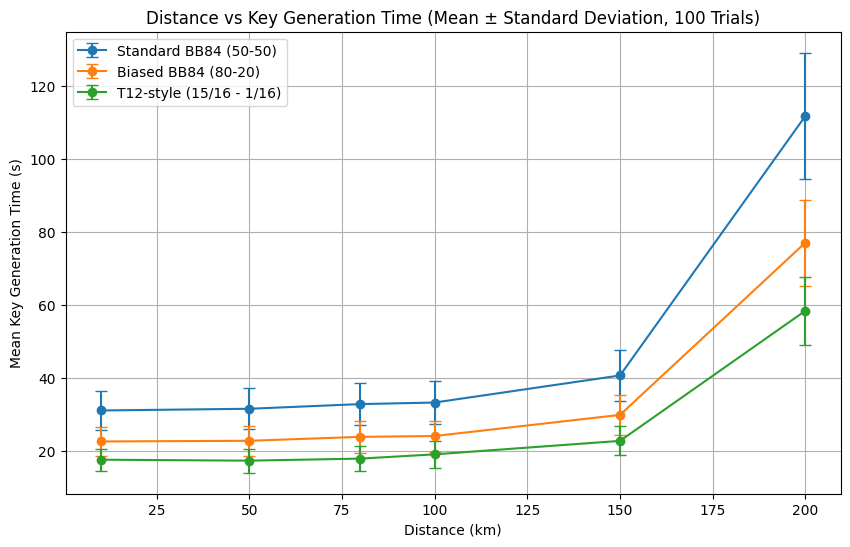

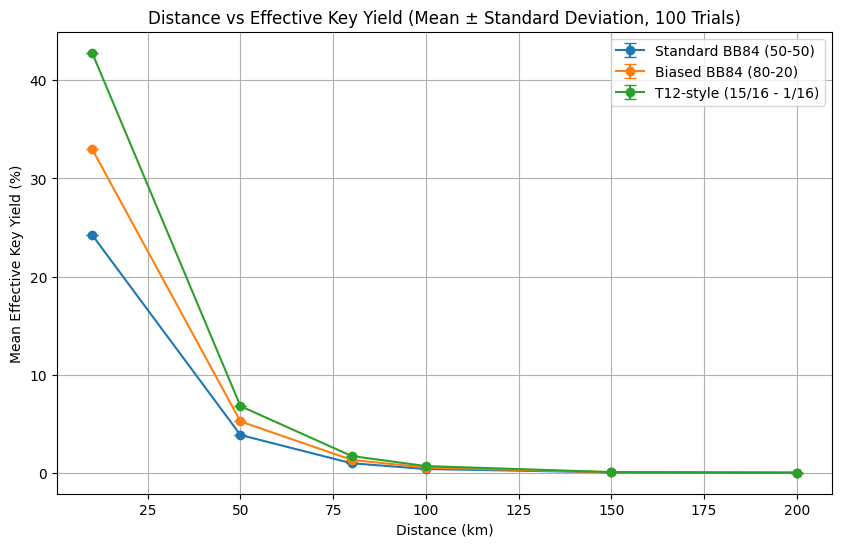

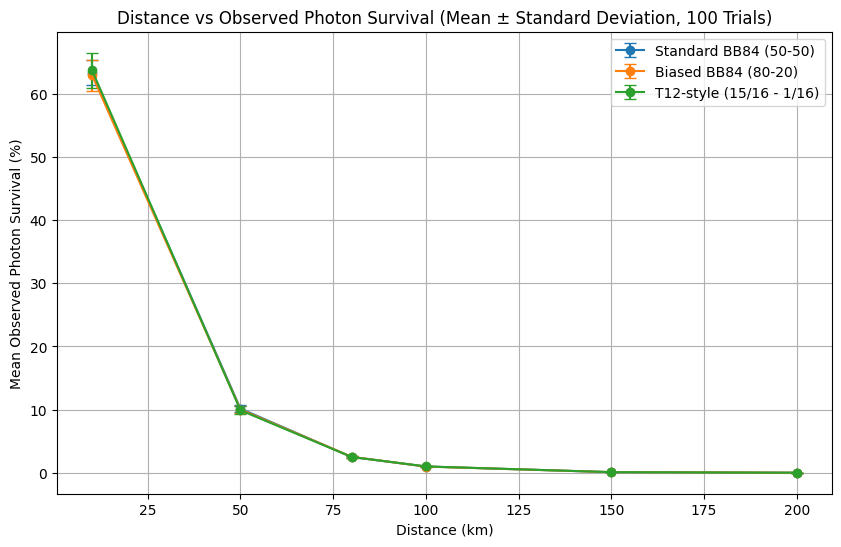

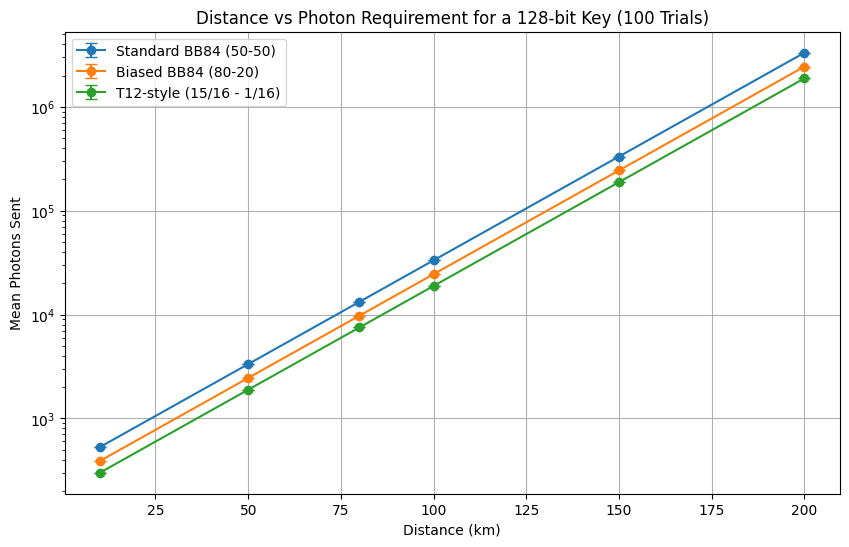

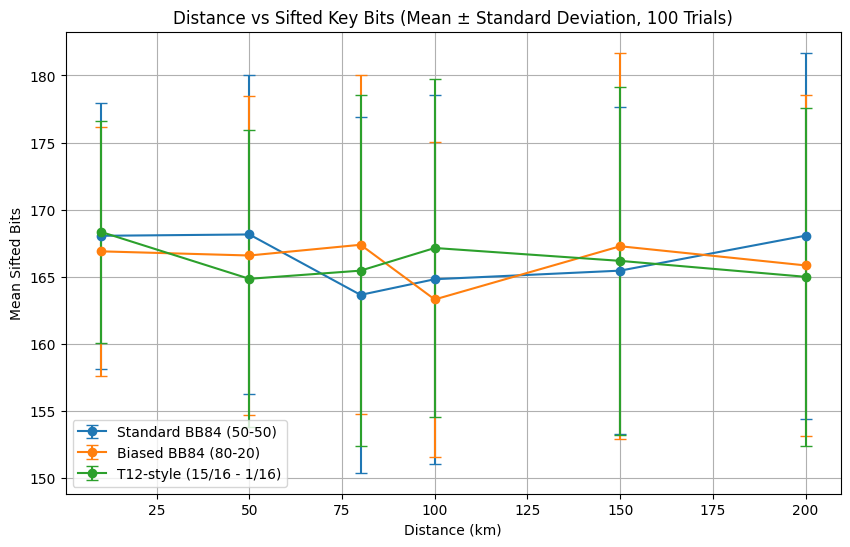

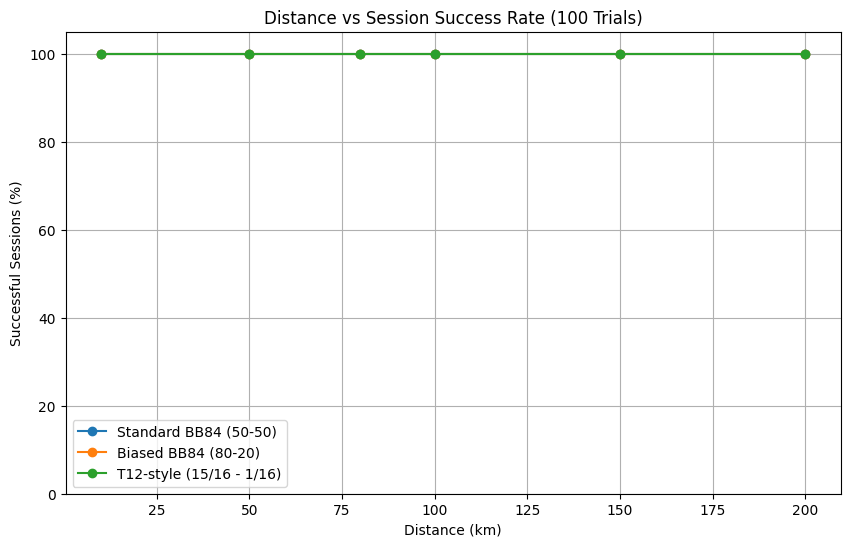

In [ ]:
# @title Phase 1 Monte Carlo Paper-Ready Graphs

# import matplotlib.pyplot as plt
# import pandas as pd

# summary_df = pd.read_csv(
#     "phase1_monte_carlo_summary_100_trials.csv"
# )

# phase1_plot_protocols = [
#     "Standard BB84 (50-50)",
#     "Biased BB84 (80-20)",
#     "T12-style (15/16 - 1/16)"
# ]


# # =========================================================
# # Graph 1: Distance vs mean key-generation time

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Keygen Time (s) mean"],
#         yerr=subset["Keygen Time (s) std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Key Generation Time (s)")
# plt.title(
#     "Distance vs Key Generation Time "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Key Generation Time.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 2: Distance vs mean effective key yield

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Effective Key Yield (%) mean"],
#         yerr=subset["Effective Key Yield (%) std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Effective Key Yield (%)")
# plt.title(
#     "Distance vs Effective Key Yield "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Effective Key Yield.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 3: Distance vs observed photon survival

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset[
#             "Observed Photon Survival (%) mean"
#         ],
#         yerr=subset[
#             "Observed Photon Survival (%) std"
#         ],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Observed Photon Survival (%)")
# plt.title(
#     "Distance vs Observed Photon Survival "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Observed Photon Survival.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 4: Distance vs photons required

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Photons Sent mean"],
#         yerr=subset["Photons Sent std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Photons Sent")
# plt.title(
#     "Distance vs Photon Requirement for a "
#     "128-bit Key (100 Trials)"
# )
# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Photons Required.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 5: Distance vs sifted bits

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Sifted Bits mean"],
#         yerr=subset["Sifted Bits std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Sifted Bits")
# plt.title(
#     "Distance vs Sifted Key Bits "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Sifted Bits.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 6: Success rate

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.plot(
#         subset["Distance (km)"],
#         subset["Success Rate (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Successful Sessions (%)")
# plt.title(
#     "Distance vs Session Success Rate "
#     "(100 Trials)"
# )
# plt.ylim(0, 105)
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Session Success Rate.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

## Phase 2 : 07-07-2026T16:50:12 -- 09-07-2026T02:17:32

Goal : Add a single repeater so that Alice <--> Bob chain becomes ===> Alice <--> R1 <--> Bob


Objective : Measure whether splitting distance improves stability and key availability.

Question : Can a single repeater improve the effective QKD range and reliability compared to direct transmission?

### Phase 2A

Single Quantum Repeater Abstraction

In [ ]:
# @title Single Repeater Node

r1 = Node(name="R1", role=ROLE_REPEATER)

print(r1)

In [ ]:
# @title Bell Pair Abstraction

class BellPair:
    """
    Represents an entangled Bell pair between two nodes.

    In Phase 2A, this is a network-level abstraction.
    It does not simulate the full photonic hardware circuit.
    """

    def __init__(
        self,
        node_a: Node,
        node_b: Node,
        fidelity: float = 1.0,
        source_link_distance_km: float = None
    ):
        self.node_a = node_a
        self.node_b = node_b
        self.fidelity = fidelity
        self.source_link_distance_km = source_link_distance_km

    def involves(self, node: Node) -> bool:
        return self.node_a == node or self.node_b == node

    def other_node(self, node: Node) -> Node:
        if self.node_a == node:
            return self.node_b
        if self.node_b == node:
            return self.node_a

        raise ValueError("Node is not part of this Bell pair.")

    def __str__(self):
        return (
            f"BellPair({self.node_a.name} ↔ {self.node_b.name}, "
            f"F={self.fidelity:.4f})"
        )

In [ ]:
# @title Bell Pair Generation Attempt

def attempt_bell_pair_generation(
    link: QuantumLink,
    source_fidelity: float = 1.0
):
    """
    Attempt to generate a Bell pair across one elementary quantum link.

    Phase 2A abstraction:
    - Success probability is approximated using link photon survival probability.
    - Successful attempt returns a BellPair object.
    - Failed attempt returns None.
    """

    if random.random() < link.survival_probability:
        return BellPair(
            node_a=link.source,
            node_b=link.destination,
            fidelity=source_fidelity,
            source_link_distance_km=link.distance_km
        )

    return None

In [ ]:
# @title Entanglement Swapping

def entanglement_swap(
    left_pair: BellPair,
    right_pair: BellPair,
    repeater: Node,
    swapping_success_probability: float = 1.0
):
    """
    Perform entanglement swapping at the repeater.

    Example:
        left_pair  = BellPair(Alice ↔ R1)
        right_pair = BellPair(R1 ↔ Bob)

    Output:
        BellPair(Alice ↔ Bob)

    The repeater does not learn the key/message.
    It only helps convert two elementary entangled links
    into one end-to-end entangled link.
    """

    if left_pair is None or right_pair is None:
        return None

    if not left_pair.involves(repeater):
        raise ValueError("Left Bell pair does not involve the repeater.")

    if not right_pair.involves(repeater):
        raise ValueError("Right Bell pair does not involve the repeater.")

    if random.random() > swapping_success_probability:
        return None

    end_a = left_pair.other_node(repeater)
    end_b = right_pair.other_node(repeater)

    combined_fidelity = left_pair.fidelity * right_pair.fidelity

    return BellPair(
        node_a=end_a,
        node_b=end_b,
        fidelity=combined_fidelity,
        source_link_distance_km=(left_pair.source_link_distance_km or 0) + (right_pair.source_link_distance_km or 0)
    )

In [ ]:
# @title Single Repeater Swapping Attempt Without Memory

def attempt_single_repeater_connection(
    link_left: QuantumLink,
    link_right: QuantumLink,
    repeater: Node,
    swapping_success_probability: float = 1.0
) -> dict:

    left_pair = attempt_bell_pair_generation(link_left)
    right_pair = attempt_bell_pair_generation(link_right)

    end_to_end_pair = None

    if left_pair is not None and right_pair is not None:
        end_to_end_pair = entanglement_swap(
            left_pair=left_pair,
            right_pair=right_pair,
            repeater=repeater,
            swapping_success_probability=swapping_success_probability
        )

    return {
        "left_pair": left_pair,
        "right_pair": right_pair,
        "end_to_end_pair": end_to_end_pair,
        "left_success": left_pair is not None,
        "right_success": right_pair is not None,
        "swap_success": end_to_end_pair is not None,
        "end_to_end_success": end_to_end_pair is not None,
        "left_survival_probability": link_left.survival_probability,
        "right_survival_probability": link_right.survival_probability,
        "swapping_success_probability": swapping_success_probability
    }

In [ ]:
# @title Direct vs Single Repeater Theoretical Comparison

def compare_direct_vs_single_repeater_theory(
    source: Node,
    repeater: Node,
    destination: Node,
    total_distance_km: float,
    swapping_success_probability: float = 1.0
) -> dict:

    direct_link = QuantumLink(source, destination, total_distance_km)

    segment_distance = total_distance_km / 2

    left_link = QuantumLink(source, repeater, segment_distance)
    right_link = QuantumLink(repeater, destination, segment_distance)

    direct_success_probability = direct_link.survival_probability

    no_memory_repeater_success_probability = left_link.survival_probability * right_link.survival_probability * swapping_success_probability

    direct_expected_attempts = 1 / direct_success_probability if direct_success_probability > 0 else float("inf")

    no_memory_repeater_expected_attempts = 1 / no_memory_repeater_success_probability if no_memory_repeater_success_probability > 0 else float("inf")

    return {
        "total_distance_km": total_distance_km,
        "direct_distance_km": total_distance_km,
        "segment_distance_km": segment_distance,
        "direct_success_probability": direct_success_probability,
        "left_segment_success_probability": left_link.survival_probability,
        "right_segment_success_probability": right_link.survival_probability,
        "swapping_success_probability": swapping_success_probability,
        "no_memory_repeater_success_probability": no_memory_repeater_success_probability,
        "direct_expected_attempts": direct_expected_attempts,
        "no_memory_repeater_expected_attempts": no_memory_repeater_expected_attempts
    }

In [ ]:
# @title Memory-Assisted Single Repeater Model With Bell Pairs

def generate_entanglement_via_single_repeater_with_memory(
    source: Node,
    repeater: Node,
    destination: Node,
    total_distance_km: float,
    swapping_success_probability: float = 1.0,
    memory_lifetime_attempts: int = 10000,
    max_attempts: int = 1000000,
    verbose: bool = False
) -> dict:
    """
    Memory-assisted single quantum repeater model.

    Topology:
        source ---- repeater ---- destination

    Process:
    1. Try generating BellPair(source ↔ repeater).
    2. Try generating BellPair(repeater ↔ destination).
    3. Store successful Bell pairs in quantum memory.
    4. Retry only failed side.
    5. Once both Bell pairs exist, perform entanglement swapping.
    6. Output BellPair(source ↔ destination).
    """

    segment_distance = total_distance_km / 2

    link_left = QuantumLink(source, repeater, segment_distance)
    link_right = QuantumLink(repeater, destination, segment_distance)
    direct_link = QuantumLink(source, destination, total_distance_km)

    left_pair = None
    right_pair = None

    left_memory_age = 0
    right_memory_age = 0

    left_attempts = 0
    right_attempts = 0

    swap_attempts = 0

    left_memory_expirations = 0
    right_memory_expirations = 0

    start_time = time.perf_counter()

    for global_attempt in range(1, max_attempts + 1):

        if left_pair is not None:
            left_memory_age += 1

            if left_memory_age > memory_lifetime_attempts:
                left_pair = None
                left_memory_age = 0
                left_memory_expirations += 1

        if right_pair is not None:
            right_memory_age += 1

            if right_memory_age > memory_lifetime_attempts:
                right_pair = None
                right_memory_age = 0
                right_memory_expirations += 1

        if left_pair is None:
            left_attempts += 1
            generated_left = attempt_bell_pair_generation(link_left)

            if generated_left is not None:
                left_pair = generated_left
                left_memory_age = 0

        if right_pair is None:
            right_attempts += 1
            generated_right = attempt_bell_pair_generation(link_right)

            if generated_right is not None:
                right_pair = generated_right
                right_memory_age = 0

        if left_pair is not None and right_pair is not None:
            swap_attempts += 1
            end_to_end_pair = entanglement_swap(
                left_pair=left_pair,
                right_pair=right_pair,
                repeater=repeater,
                swapping_success_probability=swapping_success_probability
            )

            if end_to_end_pair is not None:
                elapsed = time.perf_counter() - start_time

                return {
                    "source": source.name,
                    "repeater": repeater.name,
                    "destination": destination.name,
                    "total_distance_km": total_distance_km,
                    "segment_distance_km": segment_distance,
                    "direct_survival_probability": direct_link.survival_probability,
                    "segment_survival_probability": link_left.survival_probability,
                    "swapping_success_probability": swapping_success_probability,
                    "memory_lifetime_attempts": memory_lifetime_attempts,
                    "global_attempts_required": global_attempt,
                    "left_attempts": left_attempts,
                    "right_attempts": right_attempts,
                    "swap_attempts": swap_attempts,
                    "left_memory_expirations": left_memory_expirations,
                    "right_memory_expirations": right_memory_expirations,
                    "final_bell_pair": str(end_to_end_pair),
                    "final_fidelity": end_to_end_pair.fidelity,
                    "success": True,
                    "time_s": elapsed
                }

            left_pair = None
            right_pair = None
            left_memory_age = 0
            right_memory_age = 0

        if verbose and global_attempt <= 20:
            print(
                f"Attempt {global_attempt}: "
                f"L_pair={left_pair is not None}, "
                f"R_pair={right_pair is not None}, "
                f"L_age={left_memory_age}, "
                f"R_age={right_memory_age}"
            )

    elapsed = time.perf_counter() - start_time

    return {
        "source": source.name,
        "repeater": repeater.name,
        "destination": destination.name,
        "total_distance_km": total_distance_km,
        "segment_distance_km": segment_distance,
        "direct_survival_probability": direct_link.survival_probability,
        "segment_survival_probability": link_left.survival_probability,
        "swapping_success_probability": swapping_success_probability,
        "memory_lifetime_attempts": memory_lifetime_attempts,
        "global_attempts_required": max_attempts,
        "left_attempts": left_attempts,
        "right_attempts": right_attempts,
        "swap_attempts": swap_attempts,
        "left_memory_expirations": left_memory_expirations,
        "right_memory_expirations": right_memory_expirations,
        "final_bell_pair": None,
        "final_fidelity": None,
        "success": False,
        "time_s": elapsed
    }

In [ ]:
# @title Single Repeater Test

result = generate_entanglement_via_single_repeater_with_memory(
    source=alice,
    repeater=r1,
    destination=bob,
    total_distance_km=100,
    swapping_success_probability=1.0,
    memory_lifetime_attempts=10000,
    max_attempts=1000000,
    verbose=True
)

print("\n")
print("=" * 70)
print("Phase 2A Single Repeater Result")
print("=" * 70)

for k, v in result.items():
    if isinstance(v, float):
        print(f"{k:<35}: {v:.6f}")
    else:
        print(f"{k:<35}: {v}")

print("=" * 70)

In [ ]:
# @title Distance Sweep Direct vs Single Repeater

phase2_distances = [50, 80, 100, 150, 200, 250, 300]

phase2_results = []

for d in phase2_distances:

    direct_link = QuantumLink(alice, bob, d)
    repeater_result = generate_entanglement_via_single_repeater_with_memory(
        source=alice,
        repeater=r1,
        destination=bob,
        total_distance_km=d,
        swapping_success_probability=1.0,
        memory_lifetime_attempts=10000,
        max_attempts=1000000,
        verbose=False
    )

    phase2_results.append({
        "Distance (km)": d,
        "Direct Survival Probability (%)": direct_link.survival_probability * 100,
        "Direct Expected Attempts": 1 / direct_link.survival_probability,
        "Segment Distance (km)": d / 2,
        "Segment Survival Probability (%)": repeater_result["segment_survival_probability"] * 100,
        "Repeater Global Attempts": repeater_result["global_attempts_required"],
        "Left Link Attempts": repeater_result["left_attempts"],
        "Right Link Attempts": repeater_result["right_attempts"],
        "Swap Attempts": repeater_result["swap_attempts"],
        "Final Bell Pair": repeater_result["final_bell_pair"],
        "Final Fidelity": repeater_result["final_fidelity"],
        "Memory Lifetime": repeater_result["memory_lifetime_attempts"],
        "Left Memory Expirations": repeater_result["left_memory_expirations"],
        "Right Memory Expirations": repeater_result["right_memory_expirations"],
        "Repeater Success": repeater_result["success"],
        "Improvement Factor": (
            (1 / direct_link.survival_probability)
            / repeater_result["global_attempts_required"]
            if repeater_result["global_attempts_required"] > 0
            else None
        )
    })

df_phase2_single_repeater = pd.DataFrame(phase2_results)

display(df_phase2_single_repeater)

df_phase2_single_repeater.to_csv(
    "phase2_single_repeater_results.csv",
    index=False
)

In [ ]:
# @title Plot : Repeater Improvement Factor

plt.figure(figsize=(10, 6))

plt.plot(
    df_phase2_single_repeater["Distance (km)"],
    df_phase2_single_repeater["Improvement Factor"],
    marker="o"
)

plt.xlabel("Total Distance (km)")
plt.ylabel("Improvement Factor")
plt.title("Single Repeater Improvement Over Direct Transmission")
plt.grid(True)

plt.savefig(
    "Phase 2 Single Repeater Improvement Over Direct Transmission.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# @title Plot : Direct Expected Attempts vs Repeater Attempts

plt.figure(figsize=(10, 6))

plt.plot(
    df_phase2_single_repeater["Distance (km)"],
    df_phase2_single_repeater["Direct Expected Attempts"],
    marker="o",
    label="Direct Expected Attempts"
)

plt.plot(
    df_phase2_single_repeater["Distance (km)"],
    df_phase2_single_repeater["Repeater Global Attempts"],
    marker="s",
    label="Single Repeater Attempts"
)

plt.xlabel("Total Distance (km)")
plt.ylabel("Attempts")
plt.title("Direct Transmission vs Single Repeater Attempts")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.savefig(
    "Phase 2 Direct vs Repeater Attempts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Phase 2B

Repeater Assisted QKD Protocols --> AES Key Generation

In [ ]:
# @title Physical Bell Pair Generation

def attempt_bell_pair_generation_physical(
    link: QuantumLink,
    source_fidelity: float = 1.0
):
    """
    Attempts Bell-pair generation over a physical QuantumLink.

    This uses QuantumLink.transmit(), so fiber attenuation and photon loss
    are recorded in the physical layer statistics.
    """

    received = link.transmit("photon")

    if received is not None:
        return BellPair(
            node_a=link.source,
            node_b=link.destination,
            fidelity=source_fidelity,
            source_link_distance_km=link.distance_km
        )

    return None

In [ ]:
# @title Repeater-Assisted Quantum Channel With Layered Statistics

class RepeaterAssistedQuantumChannel:
    """
    Repeater-assisted quantum channel.

    Physical Layer:
    - photons emitted
    - photons survived/lost
    - Bell-pair generation attempts
    - memory expirations
    - entanglement swapping attempts

    Quantum Protocol Layer:
    - qubits requested
    - qubits delivered
    - qubits lost at protocol level
    """

    def __init__(
        self,
        source: Node,
        repeater: Node,
        destination: Node,
        total_distance_km: float,
        swapping_success_probability: float = 1.0,
        memory_lifetime_attempts: int = 10000,
        max_entanglement_attempts: int = 1000000
    ):
        self.source = source
        self.repeater = repeater
        self.destination = destination

        self.total_distance_km = total_distance_km
        self.segment_distance_km = total_distance_km / 2

        self.swapping_success_probability = swapping_success_probability
        self.memory_lifetime_attempts = memory_lifetime_attempts
        self.max_entanglement_attempts = max_entanglement_attempts

        self.left_link = QuantumLink(source, repeater, self.segment_distance_km)
        self.right_link = QuantumLink(repeater, destination, self.segment_distance_km)
        self.direct_link = QuantumLink(source, destination, total_distance_km)

        self.physical_stats = {
            "left_photons_sent": 0,
            "left_photons_survived": 0,
            "left_photons_lost": 0,

            "right_photons_sent": 0,
            "right_photons_survived": 0,
            "right_photons_lost": 0,

            "left_bell_pair_attempts": 0,
            "right_bell_pair_attempts": 0,

            "successful_left_bell_pairs": 0,
            "successful_right_bell_pairs": 0,
            "successful_end_to_end_bell_pairs": 0,

            "swap_attempts": 0,

            "memory_expirations_left": 0,
            "memory_expirations_right": 0,

            "total_entanglement_attempts": 0
        }

        self.protocol_stats = {
            "qubits_requested": 0,
            "qubits_delivered": 0,
            "qubits_lost": 0
        }

    def _sync_physical_stats_from_links(self):
        self.physical_stats["left_photons_sent"] = self.left_link.statistics["lifetime_sent"]
        self.physical_stats["left_photons_survived"] = self.left_link.statistics["lifetime_received"]
        self.physical_stats["left_photons_lost"] = self.left_link.statistics["lifetime_lost"]

        self.physical_stats["right_photons_sent"] = self.right_link.statistics["lifetime_sent"]
        self.physical_stats["right_photons_survived"] = self.right_link.statistics["lifetime_received"]
        self.physical_stats["right_photons_lost"] = self.right_link.statistics["lifetime_lost"]

        self.physical_stats["total_entanglement_attempts"] = (
            self.physical_stats["left_bell_pair_attempts"]
            + self.physical_stats["right_bell_pair_attempts"]
        )

    def generate_end_to_end_bell_pair(self):
        left_pair = None
        right_pair = None

        left_memory_age = 0
        right_memory_age = 0

        for global_attempt in range(1, self.max_entanglement_attempts + 1):

            if left_pair is not None:
                left_memory_age += 1
                if left_memory_age > self.memory_lifetime_attempts:
                    left_pair = None
                    left_memory_age = 0
                    self.physical_stats["memory_expirations_left"] += 1

            if right_pair is not None:
                right_memory_age += 1
                if right_memory_age > self.memory_lifetime_attempts:
                    right_pair = None
                    right_memory_age = 0
                    self.physical_stats["memory_expirations_right"] += 1

            if left_pair is None:
                self.physical_stats["left_bell_pair_attempts"] += 1
                generated_left = attempt_bell_pair_generation_physical(self.left_link)

                if generated_left is not None:
                    left_pair = generated_left
                    left_memory_age = 0
                    self.physical_stats["successful_left_bell_pairs"] += 1

            if right_pair is None:
                self.physical_stats["right_bell_pair_attempts"] += 1
                generated_right = attempt_bell_pair_generation_physical(self.right_link)

                if generated_right is not None:
                    right_pair = generated_right
                    right_memory_age = 0
                    self.physical_stats["successful_right_bell_pairs"] += 1

            if left_pair is not None and right_pair is not None:
                self.physical_stats["swap_attempts"] += 1

                end_to_end_pair = entanglement_swap(
                    left_pair=left_pair,
                    right_pair=right_pair,
                    repeater=self.repeater,
                    swapping_success_probability=self.swapping_success_probability
                )

                if end_to_end_pair is not None:
                    self.physical_stats["successful_end_to_end_bell_pairs"] += 1
                    self._sync_physical_stats_from_links()

                    return {
                        "success": True,
                        "end_to_end_pair": end_to_end_pair,
                        "global_attempts_required": global_attempt
                    }

                left_pair = None
                right_pair = None
                left_memory_age = 0
                right_memory_age = 0

        self._sync_physical_stats_from_links()

        return {
            "success": False,
            "end_to_end_pair": None,
            "global_attempts_required": self.max_entanglement_attempts
        }

    def transmit(self, qubit):
        self.protocol_stats["qubits_requested"] += 1

        result = self.generate_end_to_end_bell_pair()

        if result["success"]:
            self.protocol_stats["qubits_delivered"] += 1
            return qubit

        self.protocol_stats["qubits_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        transmitted_qubits = [self.transmit(q) for q in qubits]

        sent = len(qubits)
        delivered = sum(q is not None for q in transmitted_qubits)
        lost = sent - delivered

        self._sync_physical_stats_from_links()

        avg_attempts_per_delivered_qubit = (
            self.physical_stats["total_entanglement_attempts"] / delivered
            if delivered else None
        )

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": delivered,
            "lost": lost,
            "observed_survival_probability": delivered / sent if sent else 0,
            "physical_stats": self.physical_stats.copy(),
            "protocol_stats": self.protocol_stats.copy(),
            "average_entanglement_attempts_per_delivered_qubit": avg_attempts_per_delivered_qubit
        }

In [ ]:
# @title BB84 Round Over Repeater-Assisted Channel

def bb84_round_over_repeater_channel(
    channel: RepeaterAssistedQuantumChannel,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    # Important:
    # In repeater-assisted mode, fiber attenuation is paid inside Bell-pair generation.
    # Therefore protocol qubit budget depends only on basis matching.
    estimated_qubits_required = math.ceil(
        (target_bits * transmission_margin) / p_basis
    )

    alice_bits = random_bitstring(estimated_qubits_required)
    alice_bases = random_bases(estimated_qubits_required, z_probability=z_probability)
    bob_bases = random_bases(estimated_qubits_required, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = channel.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(
        received_qubits,
        bob_bases,
        eve_present=eve_present
    )

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,

        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "estimated_qubits_required": estimated_qubits_required,

        "qubits_sent": transmission["sent"],
        "qubits_received": transmission["survived"],
        "qubits_lost": transmission["lost"],

        "physical_stats": transmission["physical_stats"],
        "protocol_stats": transmission["protocol_stats"],
        "average_entanglement_attempts_per_delivered_qubit":
            transmission["average_entanglement_attempts_per_delivered_qubit"]
    }

In [ ]:
# @title Generate Session Key Over Repeater-Assisted Channel

def generate_bb84_session_key_over_repeater_channel(
    channel: RepeaterAssistedQuantumChannel,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    max_rounds: int = 100,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
):

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_repeater_channel(
            channel=channel,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "qubits_sent": result["qubits_sent"],
            "qubits_received": result["qubits_received"],
            "qubits_lost": result["qubits_lost"],
            "average_entanglement_attempts_per_delivered_qubit":
                result["average_entanglement_attempts_per_delivered_qubit"]
        })

        if verbose:
            ps = result["physical_stats"]
            avg_attempts = result["average_entanglement_attempts_per_delivered_qubit"]

            print(
                f"Round {round_id}: "
                f"sent={result['qubits_sent']} | "
                f"received={result['qubits_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']} | "
                f"entanglement_attempts={ps['total_entanglement_attempts']} | "
                f"avg_attempts/qubit={avg_attempts:.2f}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough key bits over repeater-assisted channel."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_qubits_sent = sum(r["qubits_sent"] for r in round_logs)
    total_qubits_received = sum(r["qubits_received"] for r in round_logs)
    total_qubits_lost = sum(r["qubits_lost"] for r in round_logs)

    ps = channel.physical_stats
    qs = channel.protocol_stats

    total_photons_sent_physical = ps["left_photons_sent"] + ps["right_photons_sent"]
    total_photons_survived_physical = ps["left_photons_survived"] + ps["right_photons_survived"]
    total_photons_lost_physical = ps["left_photons_lost"] + ps["right_photons_lost"]

    metadata = {
        "source": channel.source.name,
        "repeater": channel.repeater.name,
        "destination": channel.destination.name,

        "total_distance_km": channel.total_distance_km,
        "segment_distance_km": channel.segment_distance_km,

        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),

        "rounds_used": len(round_logs),

        # Protocol layer
        "total_qubits_sent": total_qubits_sent,
        "total_qubits_received": total_qubits_received,
        "total_qubits_lost": total_qubits_lost,
        "effective_key_yield": target_bits / total_qubits_sent if total_qubits_sent else 0,
        "keygen_time_s": elapsed,

        # Physical layer
        "left_photons_sent": ps["left_photons_sent"],
        "left_photons_survived": ps["left_photons_survived"],
        "left_photons_lost": ps["left_photons_lost"],

        "right_photons_sent": ps["right_photons_sent"],
        "right_photons_survived": ps["right_photons_survived"],
        "right_photons_lost": ps["right_photons_lost"],

        "total_photons_sent_physical": total_photons_sent_physical,
        "total_photons_survived_physical": total_photons_survived_physical,
        "total_photons_lost_physical": total_photons_lost_physical,

        "total_entanglement_attempts": ps["total_entanglement_attempts"],
        "average_entanglement_attempts_per_delivered_qubit":
            ps["total_entanglement_attempts"] / total_qubits_received
            if total_qubits_received else None,

        "successful_end_to_end_bell_pairs": ps["successful_end_to_end_bell_pairs"],
        "swap_attempts": ps["swap_attempts"],
        "memory_expirations_left": ps["memory_expirations_left"],
        "memory_expirations_right": ps["memory_expirations_right"],

        "protocol_qubits_requested": qs["qubits_requested"],
        "protocol_qubits_delivered": qs["qubits_delivered"],
        "protocol_qubits_lost": qs["qubits_lost"],

        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Fixed Distance Protocol Comparison

test_distance = 100
target_bits = 128
transmission_margin = 1.3

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

phase2b_fixed_results = []

for protocol_name, z_prob in protocols.items():

    channel = RepeaterAssistedQuantumChannel(
        source=alice,
        repeater=r1,
        destination=bob,
        total_distance_km=test_distance,
        swapping_success_probability=1.0,
        memory_lifetime_attempts=10000,
        max_entanglement_attempts=1000000
    )

    key, meta = generate_bb84_session_key_over_repeater_channel(
        channel=channel,
        target_bits=target_bits,
        transmission_margin=transmission_margin,
        max_rounds=100,
        eve_present=False,
        z_probability=z_prob,
        verbose=False
    )

    phase2b_fixed_results.append({
        "Protocol": protocol_name,
        "Distance (km)": test_distance,
        "Segment Distance (km)": meta["segment_distance_km"],

        "Z Probability": z_prob,
        "Basis Match Probability (%)": meta["basis_match_probability"] * 100,

        "Rounds Used": meta["rounds_used"],

        # Protocol layer
        "Qubits Sent": meta["total_qubits_sent"],
        "Qubits Received": meta["total_qubits_received"],
        "Qubits Lost Protocol": meta["total_qubits_lost"],
        "Effective Key Yield (%)": meta["effective_key_yield"] * 100,

        # Physical layer
        "Left Photons Sent": meta["left_photons_sent"],
        "Left Photons Survived": meta["left_photons_survived"],
        "Left Photons Lost": meta["left_photons_lost"],

        "Right Photons Sent": meta["right_photons_sent"],
        "Right Photons Survived": meta["right_photons_survived"],
        "Right Photons Lost": meta["right_photons_lost"],

        "Total Physical Photons Sent": meta["total_photons_sent_physical"],
        "Total Physical Photons Survived": meta["total_photons_survived_physical"],
        "Total Physical Photons Lost": meta["total_photons_lost_physical"],

        "Entanglement Attempts": meta["total_entanglement_attempts"],
        "Avg Entanglement Attempts / Delivered Qubit":
            meta["average_entanglement_attempts_per_delivered_qubit"],

        "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
        "Swap Attempts": meta["swap_attempts"],

        "Keygen Time (s)": meta["keygen_time_s"]
    })

df_phase2b_fixed = pd.DataFrame(phase2b_fixed_results)

df_phase2b_fixed.to_csv(
    "phase2b_key_generation_at_100_km_with_repeater.csv",
    index=False
)

display(df_phase2b_fixed)

### Phase 2C

Single repeater assisted distances and non ideal fidelity and non ideal entanglement swapping

In [ ]:
# @title Single Repeater Distance Sweep

phase2c_distances = [10, 50, 80, 100, 150, 200]

target_bits = 128
transmission_margin = 1.3

# Ideal repeater first
source_fidelity = 1.0
swapping_success_probability = 1.0

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

phase2c_results = []

for d in phase2c_distances:
    for protocol_name, z_prob in protocols.items():

        channel = RepeaterAssistedQuantumChannel(
            source=alice,
            repeater=r1,
            destination=bob,
            total_distance_km=d,
            swapping_success_probability=swapping_success_probability,
            memory_lifetime_attempts=10000,
            max_entanglement_attempts=1000000
        )

        key, meta = generate_bb84_session_key_over_repeater_channel(
            channel=channel,
            target_bits=target_bits,
            transmission_margin=transmission_margin,
            max_rounds=100,
            eve_present=False,
            z_probability=z_prob,
            verbose=False
        )

        phase2c_results.append({
            "Protocol": protocol_name,
            "Distance (km)": d,
            "Segment Distance (km)": meta["segment_distance_km"],

            "Source Fidelity": source_fidelity,
            "Swap Success Probability": swapping_success_probability,

            "Basis Match Probability (%)": meta["basis_match_probability"] * 100,

            # Protocol layer
            "Qubits Sent": meta["total_qubits_sent"],
            "Qubits Received": meta["total_qubits_received"],
            "Qubits Lost Protocol": meta["total_qubits_lost"],
            "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
            "Keygen Time (s)": meta["keygen_time_s"],

            # Physical layer
            "Left Photons Sent": meta["left_photons_sent"],
            "Left Photons Survived": meta["left_photons_survived"],
            "Left Photons Lost": meta["left_photons_lost"],

            "Right Photons Sent": meta["right_photons_sent"],
            "Right Photons Survived": meta["right_photons_survived"],
            "Right Photons Lost": meta["right_photons_lost"],

            "Total Physical Photons Sent": meta["total_photons_sent_physical"],
            "Total Physical Photons Survived": meta["total_photons_survived_physical"],
            "Total Physical Photons Lost": meta["total_photons_lost_physical"],

            "Entanglement Attempts": meta["total_entanglement_attempts"],
            "Avg Entanglement Attempts / Delivered Qubit":
                meta["average_entanglement_attempts_per_delivered_qubit"],

            "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
            "Swap Attempts": meta["swap_attempts"],
            "Memory Expirations Left": meta["memory_expirations_left"],
            "Memory Expirations Right": meta["memory_expirations_right"]
        })

df_phase2c_distance_sweep = pd.DataFrame(phase2c_results)

df_phase2c_distance_sweep.to_csv(
    "phase2c_single_repeater_distance_sweep_ideal.csv",
    index=False
)

display(df_phase2c_distance_sweep)

In [ ]:
# @title Plot : Distance vs Entanglement Attempts

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_phase2c_distance_sweep[
        df_phase2c_distance_sweep["Protocol"] == protocol_name
    ]

    plt.plot(
        subset["Distance (km)"],
        subset["Entanglement Attempts"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Total Distance (km)")
plt.ylabel("Entanglement Attempts")
plt.title("Phase 2C: Distance vs Entanglement Attempts")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.savefig(
    "Phase 2C Distance vs Entanglement Attempts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# @title Plot : Distance vs Avg Entanglement Attempts per Delivered Qubit

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_phase2c_distance_sweep[
        df_phase2c_distance_sweep["Protocol"] == protocol_name
    ]

    plt.plot(
        subset["Distance (km)"],
        subset["Avg Entanglement Attempts / Delivered Qubit"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Total Distance (km)")
plt.ylabel("Avg Entanglement Attempts / Delivered Qubit")
plt.title("Phase 2C: Distance vs Repeater Resource Cost")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.savefig(
    "Phase 2C Distance vs Avg Entanglement Attempts per Delivered Qubit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# @title Non-Ideal Repeater Parameter Sweep

# test_distance = 100
# target_bits = 128
# transmission_margin = 1.3

# source_fidelities = [1.0, 0.98, 0.95, 0.90]
# swap_success_probabilities = [1.0, 0.95, 0.90, 0.80]

# # Keep T12 here first because it is most efficient.
# # Later we can repeat this for all protocols if needed.
# test_protocol_name = "T12-style (15/16 - 1/16)"
# test_z_probability = 15/16

# nonideal_results = []

# for sf in source_fidelities:
#     for p_swap in swap_success_probabilities:

#         # Patch: use source fidelity in Bell-pair generation by temporarily setting global wrapper.
#         # For now, fidelity affects final BellPair fidelity but not success probability.
#         # Swap probability affects whether entanglement swapping succeeds.

#         channel = RepeaterAssistedQuantumChannel(
#             source=alice,
#             repeater=r1,
#             destination=bob,
#             total_distance_km=test_distance,
#             swapping_success_probability=p_swap,
#             memory_lifetime_attempts=10_000,
#             max_entanglement_attempts=1_000_000
#         )

#         key, meta = generate_bb84_session_key_over_repeater_channel(
#             channel=channel,
#             target_bits=target_bits,
#             transmission_margin=transmission_margin,
#             max_rounds=100,
#             eve_present=False,
#             z_probability=test_z_probability,
#             verbose=False
#         )

#         # Approximate final fidelity:
#         # One end-to-end Bell pair combines two elementary Bell pairs.
#         # For sf on each elementary pair: final ≈ sf^2
#         # If swap is imperfect, include swap success quality separately later.
#         approx_final_fidelity = sf ** 2

#         nonideal_results.append({
#             "Protocol": test_protocol_name,
#             "Distance (km)": test_distance,
#             "Source Fidelity": sf,
#             "Swap Success Probability": p_swap,
#             "Approx Final Fidelity": approx_final_fidelity,
#             "Qubits Sent": meta["total_qubits_sent"],
#             "Qubits Received": meta["total_qubits_received"],
#             "Entanglement Attempts": meta["total_entanglement_attempts"],
#             "Avg Entanglement Attempts / Delivered Qubit":
#                 meta["average_entanglement_attempts_per_delivered_qubit"],
#             "Swap Attempts": meta["swap_attempts"],
#             "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
#             "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#             "Keygen Time (s)": meta["keygen_time_s"]
#         })

# df_phase2c_nonideal = pd.DataFrame(nonideal_results)

# df_phase2c_nonideal.to_csv(
#     "phase2c_nonideal_repeater_parameter_sweep.csv",
#     index=False
# )

# display(df_phase2c_nonideal)